IndiaKart E-Commerce Analysis - Phase2

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import os
os.makedirs("../Charts", exist_ok=True)

Objective:  
The objective of Phase 2 is to perform exploratory data analysis on the IndiaKart e-commerce dataset and identify important patterns in orders, revenue, customers, payments, and returns.

Data Loading:

In [51]:
orders = pd.read_csv(
    "../Cleaned Data/orders_cleaned.csv",
    parse_dates=["order_date", "delivered_date"]
)

In [4]:
order_items = pd.read_csv('../Cleaned Data/order_items_cleaned.csv')

In [26]:
customers = pd.read_csv(
    '../Cleaned Data/customers_cleaned.csv',
    parse_dates = ['registration_date','last_login_date']
)

In [9]:
payments = pd.read_csv(
    '../Cleaned Data/payments_cleaned.csv',
    parse_dates = ['payment_date','refund_date']
)

In [16]:
returns = pd.read_csv(
    '../Cleaned Data/returns_cleaned.csv',
     parse_dates = ['return_date','refund_date']
)

1.	Monthly order volume — a bar or line chart showing number of orders per month for all      24 months. Highlight the Diwali months (Oct, Nov).

In [4]:
orders.head()

,order_id,customer_id,order_date,order_time,status,city,state,pincode,total_amount,gst_amount,shipping_charge,discount_amount,final_amount,payment_method,shipping_partner,tracking_id,delivered_date,is_cod,channel
0,ORD000001,CUST02946,2025-05-22,17:10:00,Processing,Pune,Maharashtra,300862,100984.19,16364.64,0,20486.45,100984.19,Cash on Delivery,BlueDart,TRK354572763,NaT,1,App
1,ORD000002,CUST04232,2023-10-16,05:32:00,Delivered,Ludhiana,Punjab,387852,254478.01,41599.80,0,19338.79,254478.01,UPI,DTDC,TRK272838570,2023-10-19,0,Website
2,ORD000003,CUST08078,2023-10-08,12:32:00,Cancelled,Meerut,Uttar Pradesh,294014,32557.06,3562.92,0,696.86,32557.06,Debit Card,Amazon Logistics,TRK338505401,NaT,0,App
3,ORD000004,CUST09612,2023-10-02,08:05:00,Delivered,Nashik,Maharashtra,626047,24836.94,3092.88,0,4029.94,24836.94,UPI,DTDC,TRK289792017,2023-10-09,0,Mobile Web
4,ORD000005,CUST03065,2024-06-15,20:19:00,Delivered,Moradabad,Uttar Pradesh,409210,156689.29,25092.36,0,7805.07,156689.29,UPI,Ecom Express,TRK978240041,2024-06-22,0,App


In [63]:
orders['month'] = orders['order_date'].dt.to_period('M')

In [64]:
monthly_orders = orders.groupby('month').size().reset_index(name='order_count')

In [65]:
monthly_orders.head()

,month,order_count
0,2023-06,444
1,2023-07,2081
2,2023-08,2091
3,2023-09,2104
4,2023-10,2060


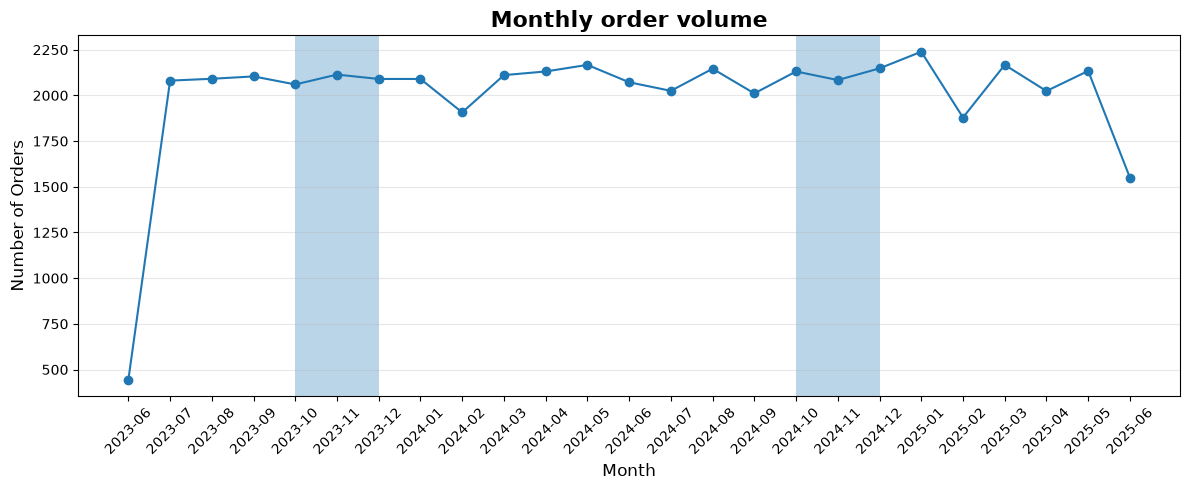

In [91]:
plt.figure(figsize=(12,5))

plt.plot(
    monthly_orders['month'].astype(str),
    monthly_orders['order_count'],
    marker='o'
)

# Highlight October and November
for i, month in enumerate(monthly_orders["month"].astype(str)):
    if month.endswith("-10") or month.endswith("-11"):
        plt.axvspan(i - 0, i + 1, alpha=0.3)

plt.title('Monthly order volume', fontsize=16, fontweight='bold')
plt.xlabel('Month', fontsize=12)
plt.ylabel('Number of Orders', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('../Charts/monthly_orders.png', dpi=300, bbox_inches='tight')

plt.show()

In [47]:
orders.columns

Index(['order_id', 'customer_id', 'order_date', 'order_time', 'status', 'city',
       'state', 'pincode', 'total_amount', 'gst_amount', 'shipping_charge',
       'discount_amount', 'final_amount', 'payment_method', 'shipping_partner',
       'tracking_id', 'delivered_date', 'is_cod', 'channel', 'month'],
      dtype='str')

Observation:   Order volume increased sharply from June to July 2023 and then remained at a relatively high level in the following months. The monthly trend shows how order activity changed over time and can help identify periods of higher or lower demand.

2.	Monthly revenue (GMV) — same as above but using final_amount. Compare year-over-year.

In [67]:
monthly_revenue = orders.groupby('month')['final_amount'].sum().reset_index()

In [68]:
monthly_revenue['final_amount'] = monthly_revenue['final_amount']/1000000

In [69]:
monthly_revenue.head()

,month,final_amount
0,2023-06,27.384849
1,2023-07,128.920509
2,2023-08,128.122037
3,2023-09,137.462483
4,2023-10,132.470874


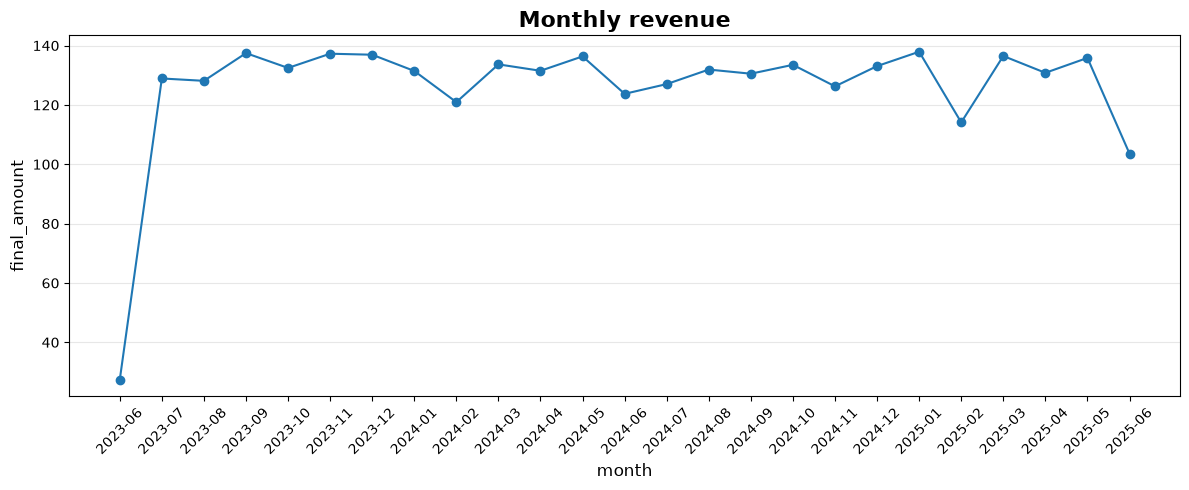

In [90]:
plt.figure(figsize=(12,5))

plt.plot(
    monthly_revenue['month'].astype(str),
    monthly_revenue['final_amount'],
    marker='o'
)

plt.title('Monthly revenue', fontsize=16, fontweight='bold')
plt.xlabel('month', fontsize=12)
plt.ylabel('final_amount', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('../Charts/monthly_revenue.png', dpi=300, bbox_inches='tight')

Observation: The monthly revenue shows an overall increasing trend with some fluctuations across the months.
Revenue was highest in September 2023 among the first few months shown, while June 2023 recorded a much lower value.

3.	Category-wise revenue share — a pie chart or horizontal bar chart. Which category          earns the most?

In [6]:
order_items.head()

,item_id,order_id,product_id,product_name,category,quantity,unit_price,gst_rate,gst_amount,discount_amount,total_price
0,ITM0000001,ORD000001,PRD0522,HCL Cricket Bat Ultra,Sports & Fitness,1,40989,12,4918.68,7861.45,38046.23
1,ITM0000002,ORD000001,PRD0094,Berger Router Pro,Electronics,1,62532,18,11255.76,12373.11,61414.65
2,ITM0000003,ORD000001,PRD0613,Voltas Educational Toy Standard,Toys & Baby,1,1585,12,190.20,251.89,1523.31
3,ITM0000004,ORD000002,PRD0556,Ambrane Cycle Standard,Sports & Fitness,3,1107,12,398.52,631.44,3088.08
4,ITM0000005,ORD000002,PRD0026,Pebble Tablet Premium,Electronics,2,114448,18,41201.28,18707.35,251389.93


In [72]:
order_items.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 11 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   item_id          100000 non-null  str    
 1   order_id         100000 non-null  str    
 2   product_id       100000 non-null  str    
 3   product_name     100000 non-null  str    
 4   category         100000 non-null  str    
 5   quantity         100000 non-null  int64  
 6   unit_price       100000 non-null  int64  
 7   gst_rate         100000 non-null  int64  
 8   gst_amount       100000 non-null  float64
 9   discount_amount  100000 non-null  float64
 10  total_price      100000 non-null  float64
dtypes: float64(3), int64(3), str(5)
memory usage: 14.2 MB


In [71]:
category_revenue = order_items.groupby('category')['total_price'].sum().reset_index()

In [72]:
category_revenue['total_price'] = category_revenue['total_price']/1000000


In [73]:
category_revenue.head()

,category,total_price
0,Automotive,123.485088
1,Beauty & Health,33.018106
2,Books,13.945894
3,Electronics,1642.422813
4,Fashion,148.155307


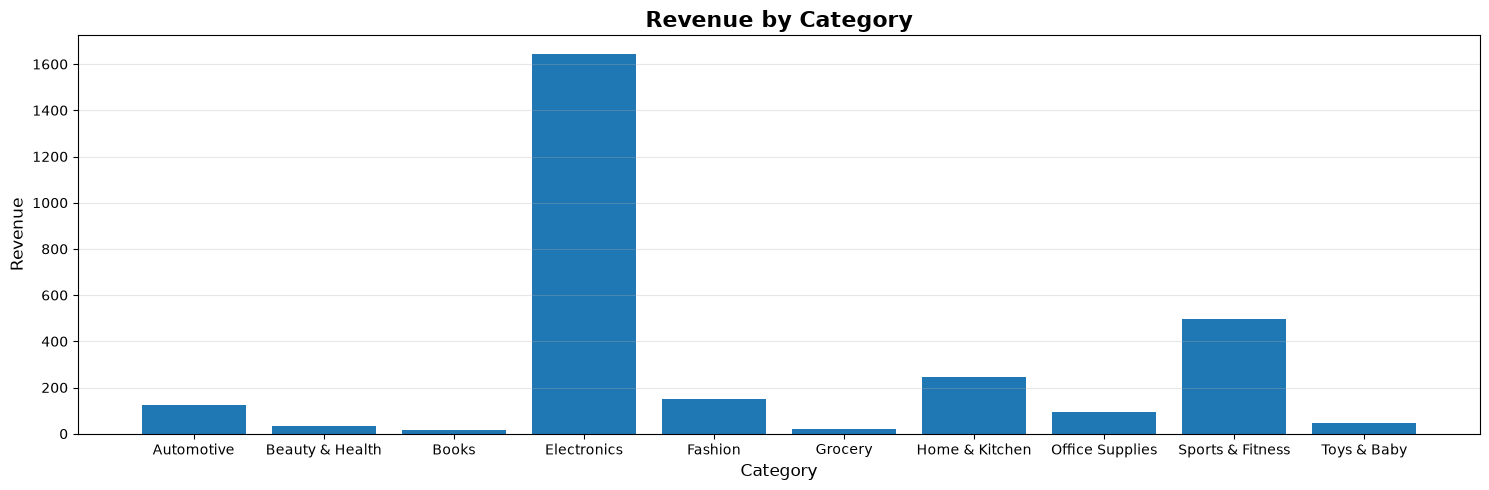

In [89]:
plt.figure(figsize=(15,5))

plt.bar(
    category_revenue['category'],
    category_revenue['total_price'],
)

plt.title('Revenue by Category', fontsize=16, fontweight='bold')
plt.xlabel('Category', fontsize=12)
plt.ylabel('Revenue', fontsize=12)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('../Charts/category_revenue.png', dpi=300, bbox_inches='tight')

plt.show()

Observation: Electronics generates the highest revenue among all product categories, followed by Sports & Fitness and Home & Kitchen.
Books and Grocery contribute the lowest revenue, while the remaining categories show moderate revenue levels.

4.	Order status distribution — a donut chart showing % of Delivered, Cancelled, Returned,     Shipped, Processing.

In [75]:
order_status = orders['status'].value_counts()

In [76]:
order_status

status
Delivered     32499
Cancelled      5996
Shipped        5071
Returned       3933
Processing     2501
Name: count, dtype: int64

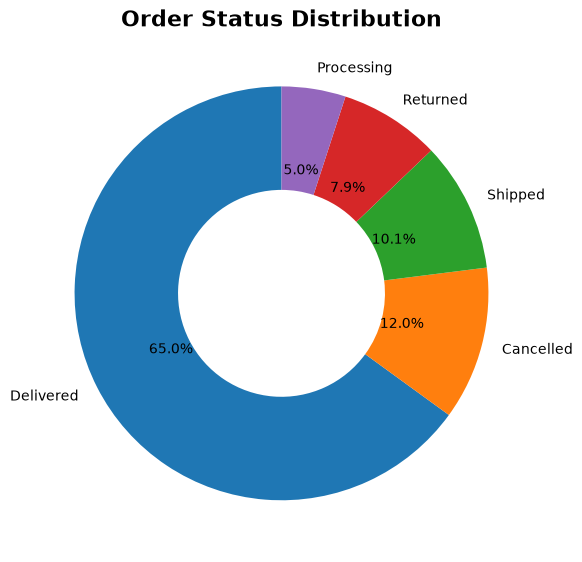

In [88]:
plt.figure(figsize=(6,6))

plt.pie(
    order_status.values,
    labels=order_status.index,
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops={"width": 0.5}
)

plt.title('Order Status Distribution', fontsize=16, fontweight='bold')

plt.tight_layout()
plt.savefig('../Charts/order_status_distribution.png', dpi=300, bbox_inches='tight')

plt.show()

Observation: Delivered orders account for the largest share at 65.0%, indicating that most orders have been successfully completed. Cancelled orders represent 12.0%, while shipped, returned, and processing orders make up smaller portions of the overall order volume.

5.	Top 10 states by number of orders — a horizontal bar chart.

In [81]:
top_states = orders['state'].value_counts().head(10)

In [82]:
top_states

state
Uttar Pradesh     9507
Maharashtra       8179
Gujarat           3811
Madhya Pradesh    3741
Tamil Nadu        3664
Karnataka         3102
Rajasthan         3047
West Bengal       2103
Punjab            2073
Jharkhand         2044
Name: count, dtype: int64

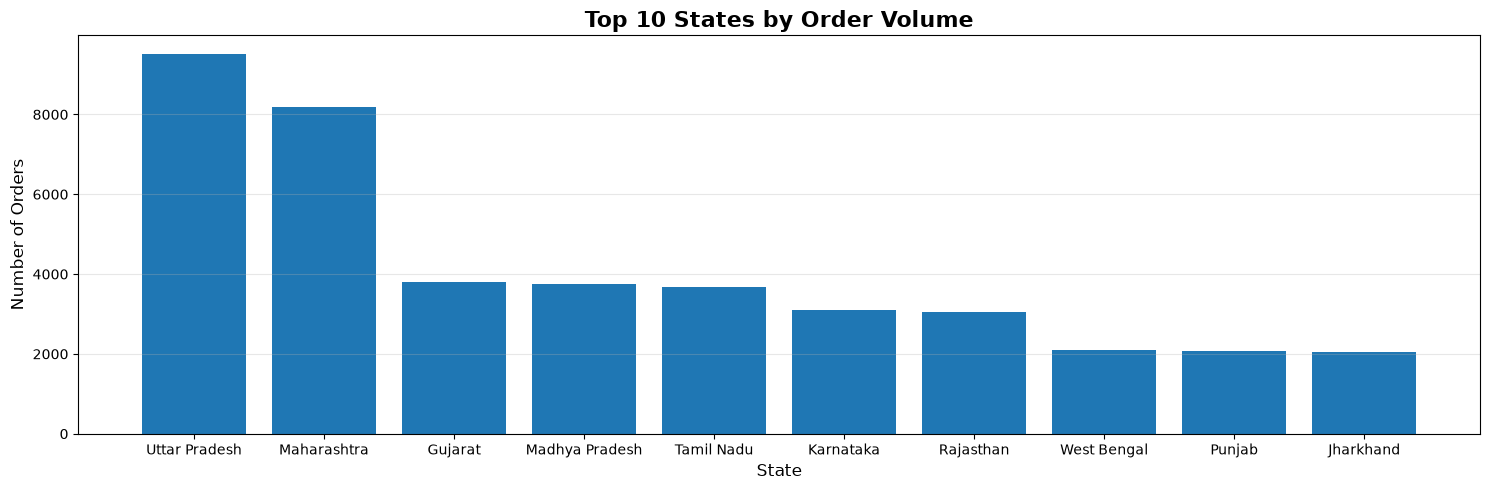

In [84]:
plt.figure(figsize=(15,5))

plt.bar(
    top_states.index,
    top_states.values,
)

plt.title('Top 10 States by Order Volume', fontsize=16, fontweight='bold')
plt.xlabel('State', fontsize=12)
plt.ylabel('Number of Orders', fontsize=12)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('../Charts/top_10_states.png', dpi=300, bbox_inches='tight')

plt.show()

Observation: Uttar Pradesh has the highest order volume among the top 10 states, followed by Maharashtra. Gujarat, Madhya Pradesh, Tamil Nadu, Karnataka, and Rajasthan show relatively similar order volumes, while West Bengal has the lowest order volume among these 10 states. Overall, the order volume is highly concentrated in Uttar Pradesh and Maharashtra compared with the other states.

6.	Customer segment distribution — a pie chart. How many Premium vs. Regular vs. Budget       customers?

In [28]:
customers.head()

,customer_id,first_name,last_name,email,phone,city,state,pincode,gender,age,segment,registration_date,last_login_date,is_verified,is_active,total_orders,total_spent
0,CUST00001,Kunal,Gupta,kunal.gupta223@gmail.com,9117912889,Guwahati,Assam,314040,Male,54,New,2024-07-30,2025-04-10,0,1,7,1028341.51
1,CUST00002,Aryan,Gupta,aryan.gupta336@yahoo.in,9271550550,Navi Mumbai,Maharashtra,799535,Female,26,Budget,2023-07-05,2024-05-03,1,1,1,20337.39
2,CUST00003,Akash,Chatterjee,akash.chatterjee584@hotmail.com,9559676548,Surat,Gujarat,738196,Female,24,Regular,2022-05-14,2023-10-31,1,1,7,265688.26
3,CUST00004,Madhuri,Walia,madhuri.walia878@gmail.com,9673322422,Gwalior,Madhya Pradesh,238106,Female,23,Regular,2025-01-21,2025-05-22,1,0,7,173446.94
4,CUST00005,Vishal,Das,vishal.das342@yahoo.in,9920855521,Dhanbad,Jharkhand,783291,Female,59,Regular,2023-06-06,2024-03-29,1,0,4,239808.60


In [33]:
customer_segment = customers[
    customers['segment'].isin(['Premium','Budget','Regular'])
    ]['segment'].value_counts()

In [34]:
customer_segment

segment
Regular    4026
Budget     2505
Premium    1501
Name: count, dtype: int64

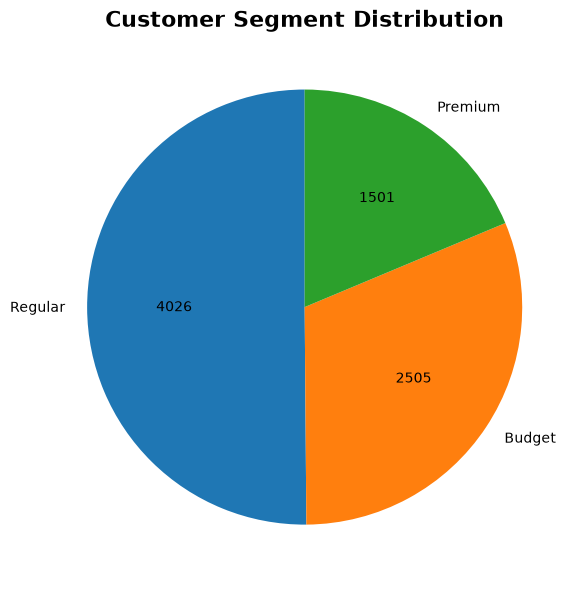

In [37]:
plt.figure(figsize=(6,6))

plt.pie(
    customer_segment.values,
    labels=customer_segment.index,
    autopct = lambda pct:f'{int(pct/100 * customer_segment.sum())}',
    startangle=90
)

plt.title("Customer Segment Distribution", fontsize=16, fontweight="bold")

plt.tight_layout()
plt.savefig("../Charts/customer_segment_distribution.png", dpi=300, bbox_inches="tight")

plt.show()

Observation:  Regular customers form the largest segment with 4,026 customers, followed by Budget customers with 2,505 customers. Premium customers are the smallest of the three segments, with 1,501 customers.

7.	Payment method usage — a bar chart showing which methods are most popular.

In [38]:
payments.head()

,payment_id,order_id,customer_id,payment_date,payment_time,payment_method,amount,status,transaction_id,bank_name,gateway,refund_amount,refund_date
0,PAY000001,ORD000001,CUST02946,2025-05-22,1900-01-01 17:10:00,Cash on Delivery,100984.19,Success,TXN5110698474,SBI,Google Pay,0,NaT
1,PAY000002,ORD000002,CUST04232,2023-10-16,1900-01-01 05:32:00,UPI,254478.01,Success,TXN4067460377,IndusInd,Google Pay,0,NaT
2,PAY000003,ORD000003,CUST08078,2023-10-08,1900-01-01 12:32:00,Debit Card,32557.06,Success,TXN7056710694,Axis Bank,PhonePe,0,NaT
3,PAY000004,ORD000004,CUST09612,2023-10-02,1900-01-01 08:05:00,UPI,24836.94,Success,TXN7460208257,Axis Bank,PhonePe,0,NaT
4,PAY000005,ORD000005,CUST03065,2024-06-15,1900-01-01 20:19:00,UPI,156689.29,Success,TXN5835043807,PNB,Razorpay,0,NaT


In [85]:
payment_method = payments["payment_method"].value_counts()

In [86]:
payment_method

payment_method
UPI                 17570
Credit Card         10007
Debit Card           7624
Cash on Delivery     5883
Net Banking          4026
EMI                  2943
Wallet               1947
Name: count, dtype: int64

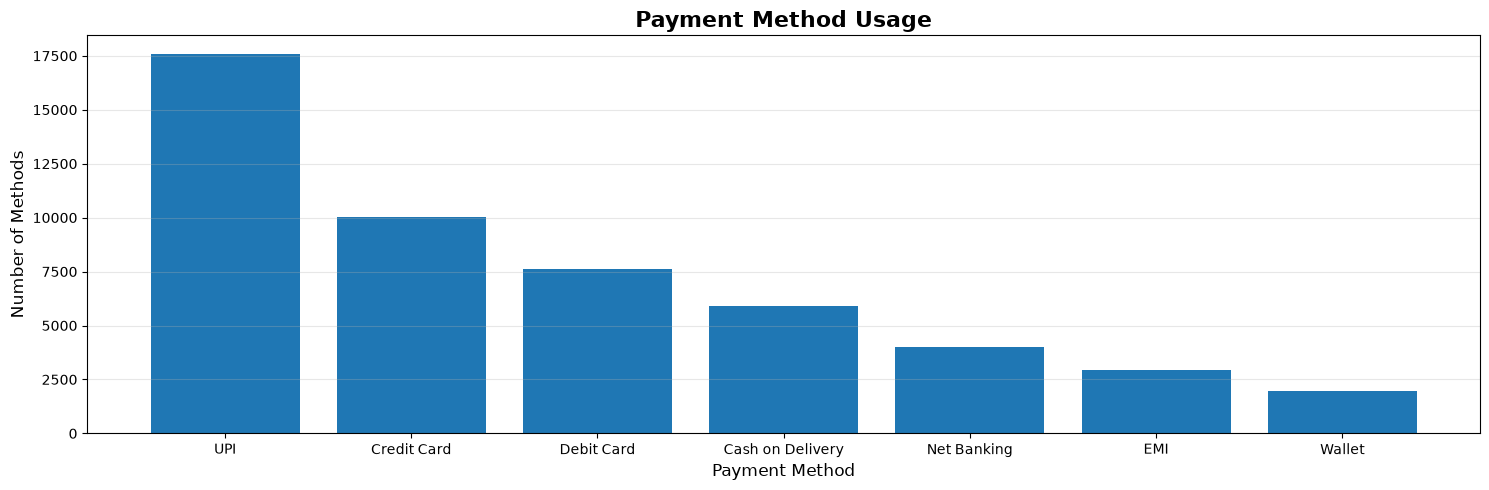

In [87]:
plt.figure(figsize=(15,5))

plt.bar(
    payment_method.index,
    payment_method.values,
)

plt.title('Payment Method Usage', fontsize=16, fontweight='bold')
plt.xlabel('Payment Method', fontsize=12)
plt.ylabel('Number of Methods', fontsize=12)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('../Charts/payment_method.png', dpi=300, bbox_inches='tight')

plt.show()

Observation:  UPI is the most widely used payment method, followed by Credit Card and Debit Card. Wallet has the lowest usage among the payment methods, while Cash on Delivery and Net Banking show moderate usage.

8.	Age distribution of customers — a histogram. What age group shops most?

In [43]:
customers['age'].describe()

count    10000.00000
mean        41.67630
std         13.83438
min         18.00000
25%         30.00000
50%         42.00000
75%         54.00000
max         65.00000
Name: age, dtype: float64

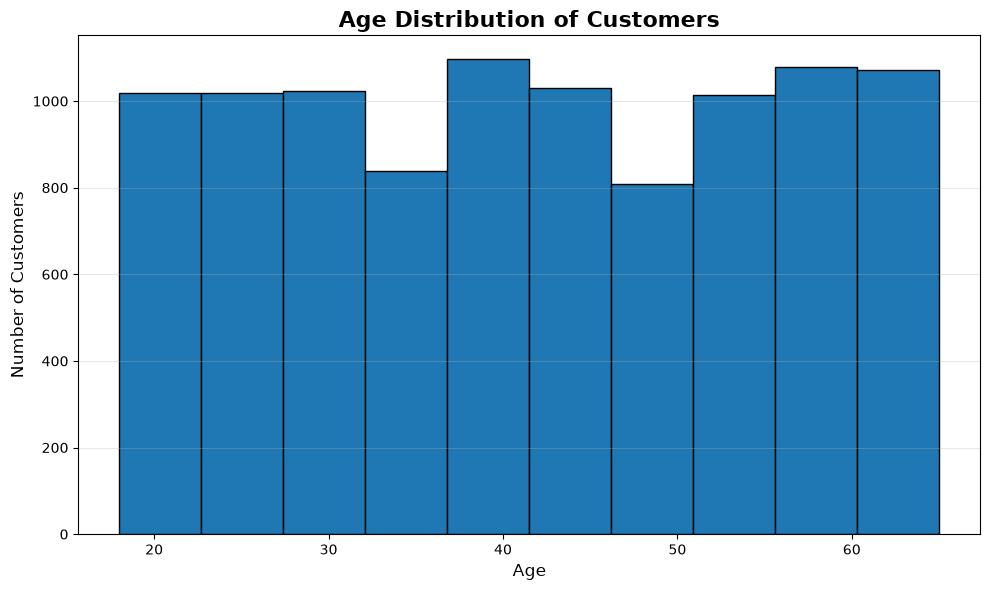

In [45]:
plt.figure(figsize=(10, 6))

plt.hist(
    customers['age'],
    bins=10,
    edgecolor='black'
)

plt.title('Age Distribution of Customers', fontsize=16, fontweight='bold')
plt.xlabel('Age', fontsize=12)
plt.ylabel('Number of Customers', fontsize=12)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('../Charts/customer_age_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

Observation:  Customer ages range from 18 to 65 years, with customers distributed across the entire age range. The 38–42 age group has the highest customer count, while the 48–52 age group has one of the lower counts.

9.	Return reasons — a bar chart of the most common return reasons from returns.csv.

In [47]:
return_reasons = returns['reason'].value_counts()

In [48]:
return_reasons

reason
Size Issue                 1196
Changed Mind               1150
Damaged in Transit         1143
Wrong Product Delivered    1135
Defective Product          1134
Not as Described           1125
Duplicate Order            1081
Quality Issue              1075
Delayed Delivery            484
Better Price Found          477
Name: count, dtype: int64

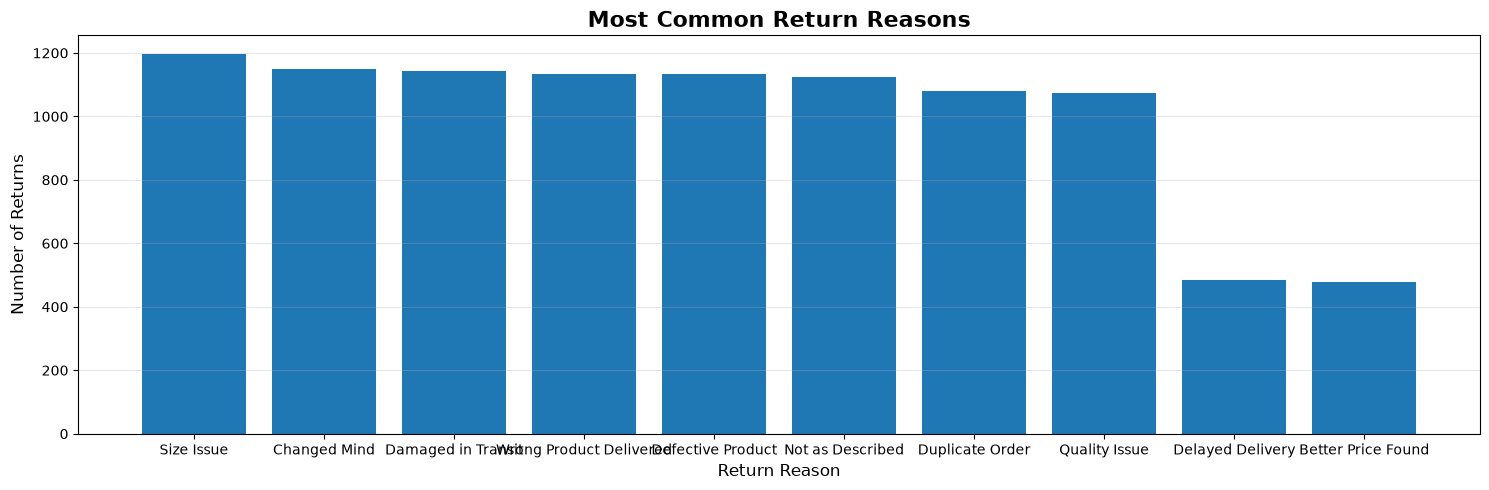

In [49]:
plt.figure(figsize=(15,5))

plt.bar(
    return_reasons.index,
    return_reasons.values,
)

plt.title('Most Common Return Reasons', fontsize=16, fontweight='bold')
plt.xlabel('Return Reason', fontsize=12)
plt.ylabel('Number of Returns', fontsize=12)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('../Charts/return_reasons.png', dpi=300, bbox_inches='tight')

plt.show()

Observation:  Size Issue is the most common return reason, with 1,196 returns, followed by Changed Mind with 1,150 returns. Better Price Found and Delayed Delivery are the least common reasons, with fewer than 500 returns each.

10.	Average Order Value (AOV) by segment — a bar chart. Do Premium customers spend more        per order?

In [52]:
orders_with_segment = orders.merge(
    customers[['customer_id','segment']],
    on = 'customer_id',
    how = 'left'
)

In [56]:
orders_with_segment[['customer_id','final_amount','segment']].head()

,customer_id,final_amount,segment
0,CUST02946,100984.19,Budget
1,CUST04232,254478.01,Inactive
2,CUST08078,32557.06,Regular
3,CUST09612,24836.94,New
4,CUST03065,156689.29,Regular


In [57]:
orders_with_segment["segment"].value_counts()

segment
Regular     23080
Premium     12923
Budget       7273
New          6453
Inactive      271
Name: count, dtype: int64

In [58]:
aov_by_segment = orders_with_segment.groupby("segment")["final_amount"].mean()

aov_by_segment

segment
Budget      64124.558428
Inactive    57120.144096
New         63381.577666
Premium     61876.903871
Regular     63123.549510
Name: final_amount, dtype: float64

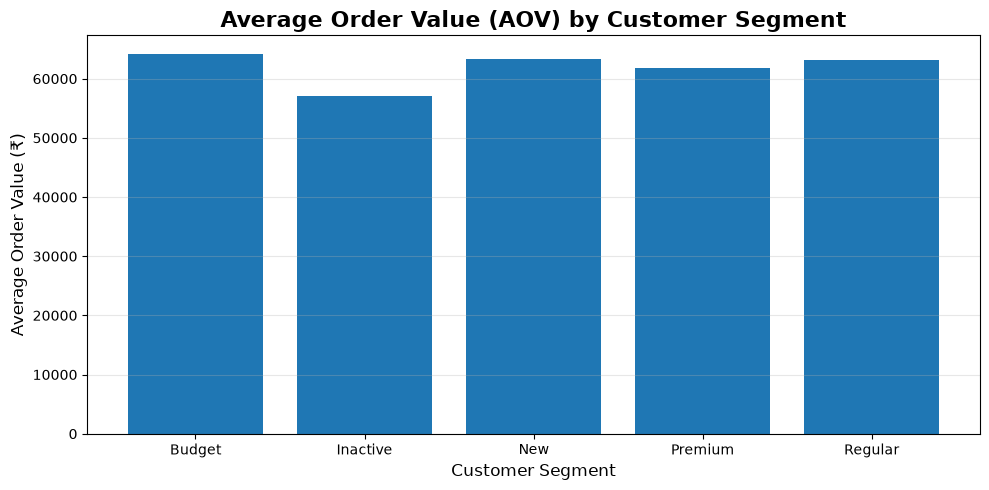

In [61]:
plt.figure(figsize=(10,5))

plt.bar(
    aov_by_segment.index,
    aov_by_segment.values,
)

plt.title('Average Order Value (AOV) by Customer Segment', fontsize=16, fontweight='bold')
plt.xlabel('Customer Segment', fontsize=12)
plt.ylabel('Average Order Value (₹)', fontsize=12)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig('../Charts/aov_by_segment.png', dpi=300, bbox_inches='tight')

plt.show()

Observation: Budget customers have the highest Average Order Value (AOV), while Inactive customers have the lowest AOV. Premium customers have a slightly lower AOV than Budget, New, and Regular customers, so Premium customers do not spend the most per order in this dataset.

Key Findings

- Order volume varies across months, with noticeable seasonal changes.
- Electronics generates the highest revenue among the product categories.
- Delivered orders represent the largest share of order statuses.
- UPI is the most commonly used payment method.
- Regular customers form the largest customer segment among Premium, Regular, and Budget customers.
- The 38–42 age group has the highest customer count.
- Size Issue is the most common reason for product returns.
- Premium customers do not have the highest AOV; Budget customers have the highest AOV in this dataset.